# Thermal emission from a thin accretion disk: a walkthrough

This notebook steps through the analysis in this repository. The questions:

* How do **black hole mass** and **accretion rate** set the disk's temperature, spectral peak and luminosity?
* What would an observer at a given **distance and inclination** measure?
* Why does the same physics put a stellar-mass black hole's disk in the **X-ray** band and a supermassive one's in the **UV**?

The disk is geometrically thin and optically thick. It is divided into concentric rings, each radiating as a blackbody at its local temperature, and the spectrum is the sum over rings. The model is in `accretion_disk/disk.py`. `scripts/run_analysis.py` produces the publication-style figures in `figures/`.

**Contents**
1. Setup
2. The radial temperature profile
3. From rings to a spectrum
4. Checking the numerical integration
5. Stellar-mass vs. supermassive black holes
6. Varying black hole mass
7. Varying accretion rate
8. What an observer sees: distance and inclination
9. Summary and limitations

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make the repository root importable whether the notebook runs from the root or from notebooks/
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "accretion_disk").is_dir())
sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt

from accretion_disk import ThinDisk, planck_nu, eddington_luminosity, constants as C

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (7.5, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "legend.frameon": False, "lines.linewidth": 1.8,
})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUE_RAMP = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
ORANGE_RAMP = ["#f6b892", "#f19a6a", "#eb6834", "#c4521f", "#9a3f14", "#6f2c0b"]

All quantities are in **CGS units**. `ThinDisk` can be built two ways:

* `ThinDisk(mass=..., mdot=...)`, with mass in grams and accretion rate in g/s, or
* `ThinDisk.from_eddington(mass_msun, eddington_ratio)`, which takes the mass in solar masses and the accretion rate as $\lambda = L/L_{\rm Edd}$.

Our two representative systems both accrete at $\lambda = 0.1$:

In [2]:
EDD_RATIO = 0.1
stellar = ThinDisk.from_eddington(10.0, EDD_RATIO)   # Galactic X-ray binary
smbh    = ThinDisk.from_eddington(1e8, EDD_RATIO)    # Seyfert / quasar nucleus

for name, d in [("Stellar-mass (10 Msun)", stellar), ("Supermassive (1e8 Msun)", smbh)]:
    print(f"{name}")
    print(f"  r_g = GM/c^2          = {d.r_g:.3e} cm")
    print(f"  r_in (ISCO, 6 r_g)    = {d.r_in:.3e} cm  ({d.r_in / 1e5:.3g} km)")
    print(f"  Mdot                  = {d.mdot:.3e} g/s = {d.mdot * C.yr / C.M_sun:.3e} Msun/yr")
    print(f"  L_Edd                 = {eddington_luminosity(d.mass):.3e} erg/s")
    print(f"  efficiency eta        = {d.efficiency:.4f}  (= 1/12)")

Stellar-mass (10 Msun)
  r_g = GM/c^2          = 1.477e+06 cm
  r_in (ISCO, 6 r_g)    = 8.860e+06 cm  (88.6 km)
  Mdot                  = 1.678e+18 g/s = 2.664e-08 Msun/yr
  L_Edd                 = 1.257e+39 erg/s
  efficiency eta        = 0.0833  (= 1/12)
Supermassive (1e8 Msun)
  r_g = GM/c^2          = 1.477e+13 cm
  r_in (ISCO, 6 r_g)    = 8.860e+13 cm  (8.86e+08 km)
  Mdot                  = 1.678e+25 g/s = 2.664e-01 Msun/yr
  L_Edd                 = 1.257e+46 erg/s
  efficiency eta        = 0.0833  (= 1/12)


## 2. The radial temperature profile

Gravitational energy released by viscous dissipation at radius $r$ is radiated locally from both disk faces. For a steady disk with no torque at the inner edge,

$$\sigma T^4(r) = \frac{3GM\dot M}{8\pi r^3}\left[1-\sqrt{\frac{r_{\rm in}}{r}}\right].$$

* Far from the hole the bracket tends to 1, so $T \propto r^{-3/4}$.
* The temperature is zero at $r_{\rm in}$ and peaks at $r = \tfrac{49}{36}r_{\rm in}$, where $T_{\max} = 0.488\,T_*$ with $T_* = (3GM\dot M/8\pi\sigma r_{\rm in}^3)^{1/4}$.

Writing radii in units of $r_g$ shows the scaling: $T \propto (\dot M / M^2)^{1/4}$. At a fixed Eddington ratio $\dot M \propto M$, so $T \propto M^{-1/4}$. **Bigger black holes have cooler disks.**

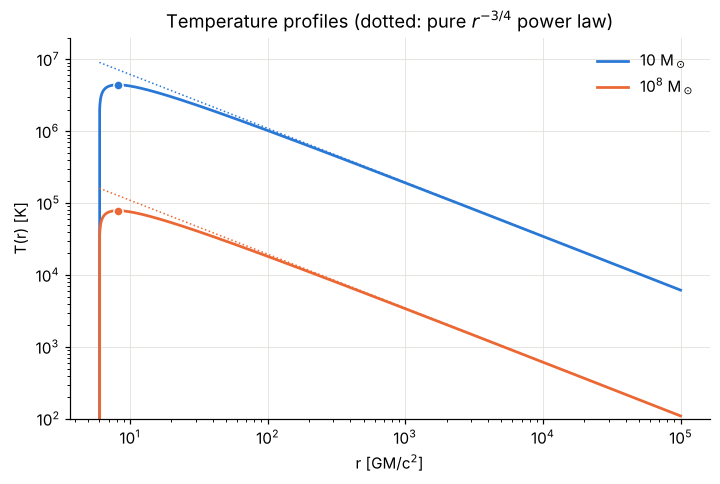

T_max stellar = 4.421e+06 K,  T_max SMBH = 7.862e+04 K
ratio = 56.23   vs   (1e8/10)^(1/4) = 56.23


In [3]:
x = np.geomspace(6.0, 1e5, 2000)        # r / r_g
fig, ax = plt.subplots()
for d, color, label in [(stellar, BLUE, r"10 M$_\odot$"), (smbh, ORANGE, r"10$^8$ M$_\odot$")]:
    ax.loglog(x, d.temperature(x * d.r_g), color=color, label=label)
    ax.loglog(x, d.T_star * (6 / x) ** 0.75, ":", lw=1, color=color)
    ax.plot(d.r_T_max / d.r_g, d.T_max, "o", color=color, mec="white")
ax.set(xlabel="r [GM/c$^2$]", ylabel="T(r) [K]", ylim=(1e2, 2e7),
       title="Temperature profiles (dotted: pure $r^{-3/4}$ power law)")
ax.legend(); plt.show()

print(f"T_max stellar = {stellar.T_max:.3e} K,  T_max SMBH = {smbh.T_max:.3e} K")
print(f"ratio = {stellar.T_max / smbh.T_max:.2f}   vs   (1e8/10)^(1/4) = {(1e7) ** 0.25:.2f}")

The two curves have the same shape and are offset by exactly $(10^7)^{1/4} \approx 56$. The supermassive disk radiates $10^7$ times more power from a surface whose area (in physical units) is $10^{14}$ times larger, so it needs a much lower temperature.

## 3. From rings to a spectrum

Each ring $k$ (temperature $T_k$, one-face area $A_k$) emits a Planck spectrum $B_\nu(T_k)$. Adding both faces and integrating over solid angle gives

$$L_\nu = 2\pi \sum_k B_\nu(T_k)\,A_k .$$

The Planck function, with overflow handling in the Wien tail, is `planck_nu`. The rings are log-spaced, so every decade in radius gets equal resolution. Here are a few individual rings and their sum:

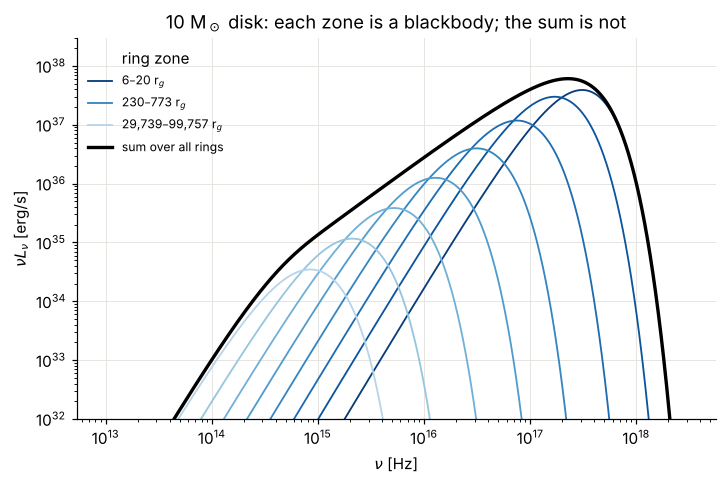

In [4]:
d = stellar
nu = np.geomspace(1e13, 3e18, 1500)
L_total = d.luminosity_nu(nu)

fig, ax = plt.subplots()
radii, T, A = d.ring_radii, d.ring_temperatures, d.ring_areas
# group the 2000 thin rings into 8 decade-ish zones so their contributions are visible
zones = np.array_split(np.arange(d.n_rings), 8)
zone_colors = plt.cm.Blues_r(np.linspace(0.05, 0.7, len(zones)))   # dark = hot inner zone
for j, (idx, color) in enumerate(zip(zones, zone_colors)):
    Lz = 2 * np.pi * planck_nu(nu[:, None], T[None, idx]) @ A[idx]
    label = f"{radii[idx[0]] / d.r_g:,.0f}–{radii[idx[-1]] / d.r_g:,.0f} r$_g$" if j in (0, 3, 7) else None
    ax.loglog(nu, nu * Lz, lw=1.2, color=color, label=label)
ax.loglog(nu, nu * L_total, color="black", lw=2.2, label="sum over all rings")
ax.set(xlabel=r"$\nu$ [Hz]", ylabel=r"$\nu L_\nu$ [erg/s]", ylim=(1e32, 3e38),
       title=r"10 M$_\odot$ disk: each zone is a blackbody; the sum is not")
ax.legend(fontsize=8, loc="upper left", title="ring zone"); plt.show()

The hot inner rings dominate the high-frequency end. The large, cool outer rings dominate the low-frequency end. Their overlapping blackbodies produce a broad **multi-temperature** spectrum with three regimes:

| Regime | Frequency range | $L_\nu$ |
|---|---|---|
| Rayleigh–Jeans | $h\nu \ll kT(r_{\rm out})$ | $\propto \nu^2$ |
| Multi-blackbody | $kT(r_{\rm out}) \ll h\nu \ll kT_{\max}$ | $\propto \nu^{1/3}$ |
| Wien cutoff | $h\nu \gg kT_{\max}$ | $\propto \nu^3 e^{-h\nu/kT_{\max}}$ |

We can measure the local slope $d\ln L_\nu / d\ln\nu$ numerically. To get a clean $\nu^{1/3}$ plateau we use a much wider disk, $r_{\rm out} = 10^8\,r_g$:

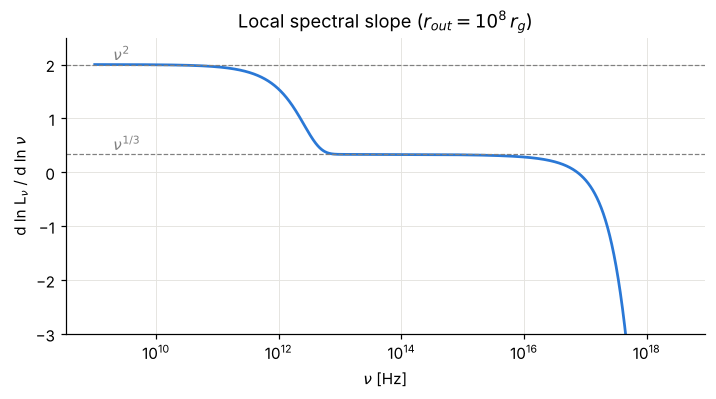

In [5]:
wide = ThinDisk.from_eddington(10.0, EDD_RATIO, r_out=1e8 * stellar.r_g, n_rings=4000)
nu = np.geomspace(1e9, 3e18, 3000)
slope = np.gradient(np.log(wide.luminosity_nu(nu)), np.log(nu))

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.semilogx(nu, slope, color=BLUE)
for s, lab in [(2, r"$\nu^2$"), (1 / 3, r"$\nu^{1/3}$")]:
    ax.axhline(s, ls="--", lw=0.8, color="gray"); ax.text(2e9, s + 0.07, lab, color="gray")
ax.set(xlabel=r"$\nu$ [Hz]", ylabel=r"d ln L$_\nu$ / d ln $\nu$", ylim=(-3, 2.5),
       title=r"Local spectral slope ($r_{out} = 10^8\,r_g$)")
plt.show()

## 4. Checking the numerical integration

There are three independent ways to get the bolometric luminosity, and they should agree:

1. **Ring sum of $\sigma T^4$:** $L = 2\sigma\sum_k T_k^4 A_k$.
2. **Integrating the spectrum:** $L = \int L_\nu\, d\nu$.
3. **The exact result** for a disk from $r_{\rm in}$ to $r_{\rm out}$ (with $X = r_{\rm out}/r_{\rm in}$):
   $$L = \frac{3GM\dot M}{2 r_{\rm in}}\left[\left(1 - \tfrac{1}{X}\right) - \tfrac{2}{3}\left(1 - X^{-3/2}\right)\right] \xrightarrow{X\to\infty} \frac{GM\dot M}{2r_{\rm in}} = \frac{\dot M c^2}{12}.$$

In [6]:
nu = stellar.frequency_grid(n=4000, low=1e-7)
L_ring = stellar.bolometric_luminosity()
L_spec = np.trapezoid(stellar.luminosity_nu(nu), nu)
L_exact = stellar.analytic_luminosity()
print(f"ring sum      L = {L_ring:.6e} erg/s   (rel. diff {L_ring / L_exact - 1:+.1e})")
print(f"int L_nu dnu  L = {L_spec:.6e} erg/s   (rel. diff {L_spec / L_exact - 1:+.1e})")
print(f"exact         L = {L_exact:.6e} erg/s")
print(f"infinite disk L = {stellar.analytic_luminosity(infinite=True):.6e} erg/s = Mdot c^2 / 12")

ring sum      L = 1.256885e+38 erg/s   (rel. diff +5.4e-06)
int L_nu dnu  L = 1.256890e+38 erg/s   (rel. diff +9.5e-06)
exact         L = 1.256878e+38 erg/s
infinite disk L = 1.257103e+38 erg/s = Mdot c^2 / 12


How many rings are needed? The error of the log-spaced midpoint sum falls as $N^{-2}$:

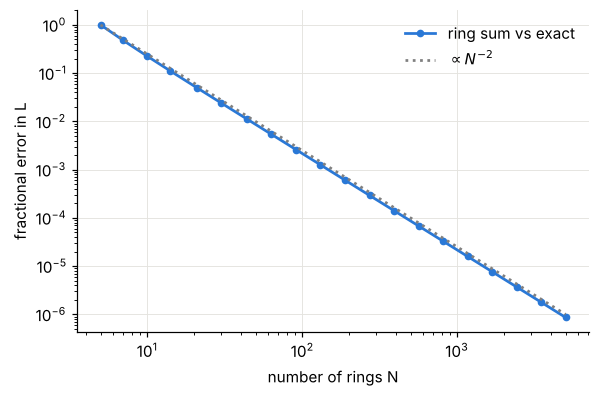

In [7]:
N = np.unique(np.geomspace(5, 5000, 20).astype(int))
err = [abs(ThinDisk.from_eddington(10, EDD_RATIO, n_rings=int(n)).bolometric_luminosity()
           / stellar.analytic_luminosity() - 1) for n in N]
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(N, err, "o-", ms=4, color=BLUE, label="ring sum vs exact")
ax.loglog(N, 25 * N ** -2.0, ":", color="gray", label=r"$\propto N^{-2}$")
ax.set(xlabel="number of rings N", ylabel="fractional error in L"); ax.legend(); plt.show()

About 100 rings already give 0.2% accuracy. The default of 2000 rings gives errors below $10^{-5}$, far smaller than the model's physical uncertainties.

## 5. Stellar-mass vs. supermassive black holes

We now compare the two fiducial systems directly. `peak_frequency()` finds the maximum of $\nu L_\nu$ and refines it with a parabola in log–log space.

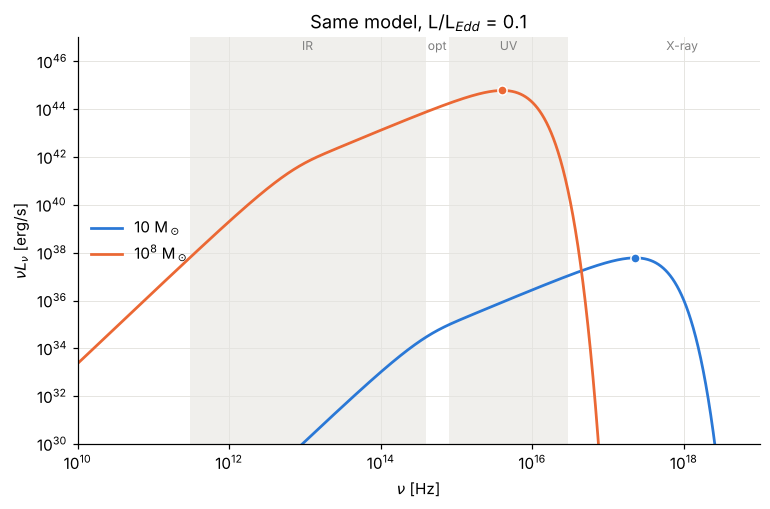

In [8]:
nu = np.geomspace(1e10, 1e19, 3000)
fig, ax = plt.subplots(figsize=(8, 4.8))
for d, color, label in [(stellar, BLUE, r"10 M$_\odot$"), (smbh, ORANGE, r"10$^8$ M$_\odot$")]:
    ax.loglog(nu, nu * d.luminosity_nu(nu), color=color, label=label)
    nu_p = d.peak_frequency()
    ax.plot(nu_p, nu_p * d.luminosity_nu(nu_p)[0], "o", color=color, mec="white")
for j, (lo, hi, name) in enumerate([(3e11, 3.9e14, "IR"), (3.9e14, 7.9e14, "opt"),
                                     (7.9e14, 3e16, "UV"), (3e16, 3e19, "X-ray")]):
    if j % 2 == 0:
        ax.axvspan(lo, hi, color="#f0efec", zorder=0, lw=0)
    ax.text(np.sqrt(lo * hi), 3e46, name, ha="center", fontsize=8, color="gray")
ax.set(xlim=(1e10, 1e19), ylim=(1e30, 1e47), xlabel=r"$\nu$ [Hz]", ylabel=r"$\nu L_\nu$ [erg/s]",
       title=f"Same model, L/L$_{{Edd}}$ = {EDD_RATIO}")
ax.legend(loc="center left"); plt.show()

In [9]:
def describe(d):
    nu_p = d.peak_frequency()
    return {
        "M [Msun]": f"{d.mass_msun:.0e}",
        "T_max [K]": f"{d.T_max:.3e}",
        "nu_peak [Hz]": f"{nu_p:.3e}",
        "E_peak [keV]": f"{C.h * nu_p / C.keV:.3g}",
        "lambda_peak [A]": f"{C.c / nu_p / C.angstrom:.3g}",
        "h nu_peak / k T_max": f"{C.h * nu_p / (C.k_B * d.T_max):.3f}",
        "L_bol [erg/s]": f"{d.bolometric_luminosity():.3e}",
    }

rows = {"stellar": describe(stellar), "SMBH": describe(smbh)}
print(f"{'':22s}{'stellar':>14s}{'SMBH':>14s}")
for key in rows["stellar"]:
    print(f"{key:22s}{rows['stellar'][key]:>14s}{rows['SMBH'][key]:>14s}")
print(f"\nnu_peak ratio = {stellar.peak_frequency() / smbh.peak_frequency():.2f}")

                             stellar          SMBH
M [Msun]                       1e+01         1e+08
T_max [K]                  4.421e+06     7.862e+04
nu_peak [Hz]               2.272e+17     4.040e+15
E_peak [keV]                    0.94        0.0167
lambda_peak [A]                 13.2           742
h nu_peak / k T_max            2.466         2.466
L_bol [erg/s]              1.257e+38     1.257e+45



nu_peak ratio = 56.23


**Interpretation.**

* The 10 $M_\odot$ disk peaks near **1 keV**, in soft X-rays. This is the thermal "disk blackbody" component seen in X-ray binaries in the high/soft state.
* The $10^8\,M_\odot$ disk peaks near **700 Å**, in the far/extreme UV. This is the "big blue bump" in quasar spectra.
* In both cases $h\nu_{\rm peak} \approx 2.47\,kT_{\max}$, because the spectrum has the same shape in units of $kT_{\max}$. The only difference between the two systems is the temperature scale, $T \propto M^{-1/4}$.

## 6. Varying black hole mass

At fixed $\lambda$, $L \propto M$ and $\nu_{\rm peak} \propto M^{-1/4}$. Spectra move up and to the left as mass increases:

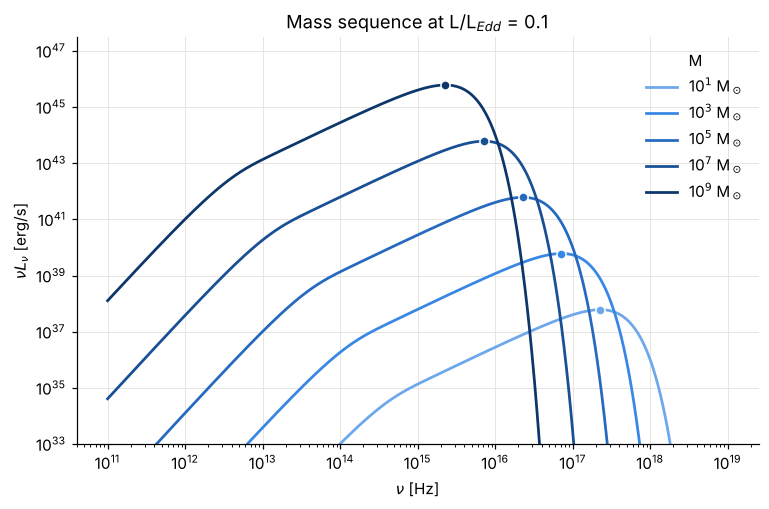

fitted d log(nu_peak) / d log(M) = -0.2500   (expected -0.25)


In [10]:
masses = [10, 1e3, 1e5, 1e7, 1e9]
nu = np.geomspace(1e11, 1e19, 2500)
fig, ax = plt.subplots(figsize=(8, 4.8))
peaks = []
for color, m in zip(BLUE_RAMP[1:], masses):
    d = ThinDisk.from_eddington(m, EDD_RATIO)
    nu_p = d.peak_frequency(); peaks.append(nu_p)
    ax.loglog(nu, nu * d.luminosity_nu(nu), color=color, label=f"10$^{{{np.log10(m):.0f}}}$ M$_\\odot$")
    ax.plot(nu_p, nu_p * d.luminosity_nu(nu_p)[0], "o", color=color, mec="white")
ax.set(ylim=(1e33, 3e47), xlabel=r"$\nu$ [Hz]", ylabel=r"$\nu L_\nu$ [erg/s]",
       title=f"Mass sequence at L/L$_{{Edd}}$ = {EDD_RATIO}")
ax.legend(title="M"); plt.show()

slope = np.polyfit(np.log10(masses), np.log10(peaks), 1)[0]
print(f"fitted d log(nu_peak) / d log(M) = {slope:.4f}   (expected -0.25)")

## 7. Varying accretion rate

At fixed mass, $L \propto \dot M$ but $\nu_{\rm peak} \propto \dot M^{1/4}$. A factor of 100 in accretion rate moves the peak by only $100^{1/4} \approx 3.2$.

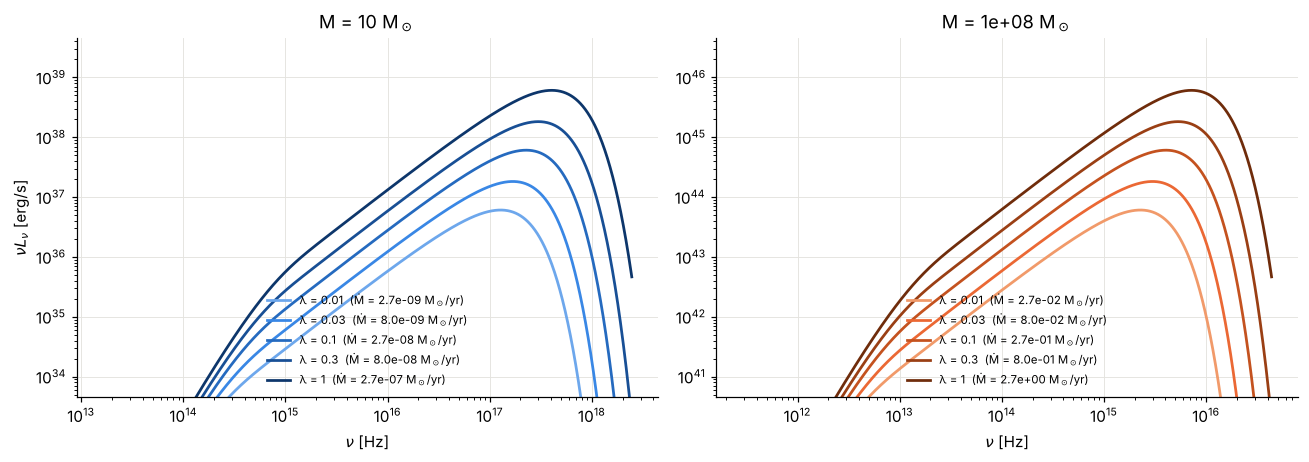

d log(nu_peak) / d log(Mdot) = 0.2500  (expected 0.25)
d log(L) / d log(Mdot)       = 1.0000  (expected 1)


In [11]:
ratios = [0.01, 0.03, 0.1, 0.3, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, m, ramp in zip(axes, (10.0, 1e8), (BLUE_RAMP, ORANGE_RAMP)):
    nu = ThinDisk.from_eddington(m, 1.0).frequency_grid(2000, low=1e-4, high=15)
    for color, lam in zip(ramp[1:], ratios):
        d = ThinDisk.from_eddington(m, lam)
        ax.loglog(nu, nu * d.luminosity_nu(nu), color=color,
                  label=f"λ = {lam:g}  (Ṁ = {d.mdot * C.yr / C.M_sun:.1e} M$_\\odot$/yr)")
    top = ax.get_ylim()[1]; ax.set_ylim(top * 1e-6, top)
    ax.set(xlabel=r"$\nu$ [Hz]", title=f"M = {m:g} M$_\\odot$")
    ax.legend(fontsize=7.5, loc="lower center")
axes[0].set_ylabel(r"$\nu L_\nu$ [erg/s]"); plt.tight_layout(); plt.show()

lam = np.geomspace(1e-3, 1, 15)
nup = [ThinDisk.from_eddington(10, l, n_rings=500).peak_frequency() for l in lam]
L = [ThinDisk.from_eddington(10, l, n_rings=500).bolometric_luminosity() for l in lam]
print(f"d log(nu_peak) / d log(Mdot) = {np.polyfit(np.log10(lam), np.log10(nup), 1)[0]:.4f}  (expected 0.25)")
print(f"d log(L) / d log(Mdot)       = {np.polyfit(np.log10(lam), np.log10(L), 1)[0]:.4f}  (expected 1)")

**Degeneracy and how to break it.** The luminosity depends only on $\dot M$ ($L = \dot M c^2/12$), not on $M$. The peak temperature depends on the combination $\dot M/M^2$. So a measurement of $L$ alone gives $\dot M$. Adding $T_{\max}$, read from the spectral peak, gives the mass:

$$M \propto \left(\frac{L}{T_{\max}^4}\right)^{1/2}.$$

The cell below recovers the mass from "observed" $L$ and $\nu_{\rm peak}$ alone:

In [12]:
def infer_mass_msun(L_bol, nu_peak):
    # Invert the model: L_bol -> Mdot, nu_peak -> T_max -> M (assumes r_in = 6 GM/c^2)
    mdot = 12 * L_bol / C.c**2                       # L = Mdot c^2 / 12
    T_max = C.h * nu_peak / (2.466 * C.k_B)          # h nu_peak = 2.466 k T_max (Sec. 5)
    T_star = T_max / ((36 / 49) ** 3 / 7) ** 0.25    # T_max = 0.488 T_*
    # sigma T_*^4 = 3 G M Mdot / (8 pi r_in^3) with r_in = 6GM/c^2  =>  M^2 = 3 G Mdot / [8 pi sigma T_*^4 (6G/c^2)^3]
    M2 = 3 * C.G * mdot / (8 * np.pi * C.sigma_SB * T_star**4 * (6 * C.G / C.c**2) ** 3)
    return np.sqrt(M2) / C.M_sun

for m_true in (10, 1e8):
    d = ThinDisk.from_eddington(m_true, 0.3)
    print(f"true M = {m_true:.3g} Msun  ->  inferred M = "
          f"{infer_mass_msun(d.bolometric_luminosity(), d.peak_frequency()):.4g} Msun")

true M = 10 Msun  ->  inferred M = 9.997 Msun


true M = 1e+08 Msun  ->  inferred M = 9.997e+07 Msun


In practice this inversion is how disk-continuum fitting constrains black hole masses and spins. It is limited by the relativistic and radiative-transfer effects discussed in §9.

## 8. What an observer sees: distance and inclination

A flat disk at distance $D$ seen at inclination $i$ (0° = face-on) presents projected area $A\cos i$, so

$$F_\nu = \frac{\cos i}{D^2}\sum_k B_\nu(T_k)\,A_k = \frac{\cos i}{2\pi D^2}\,L_\nu .$$

Our fiducial observers:
* the X-ray binary at **8 kpc**, $i = 60°$
* the AGN at **100 Mpc**, $i = 30°$

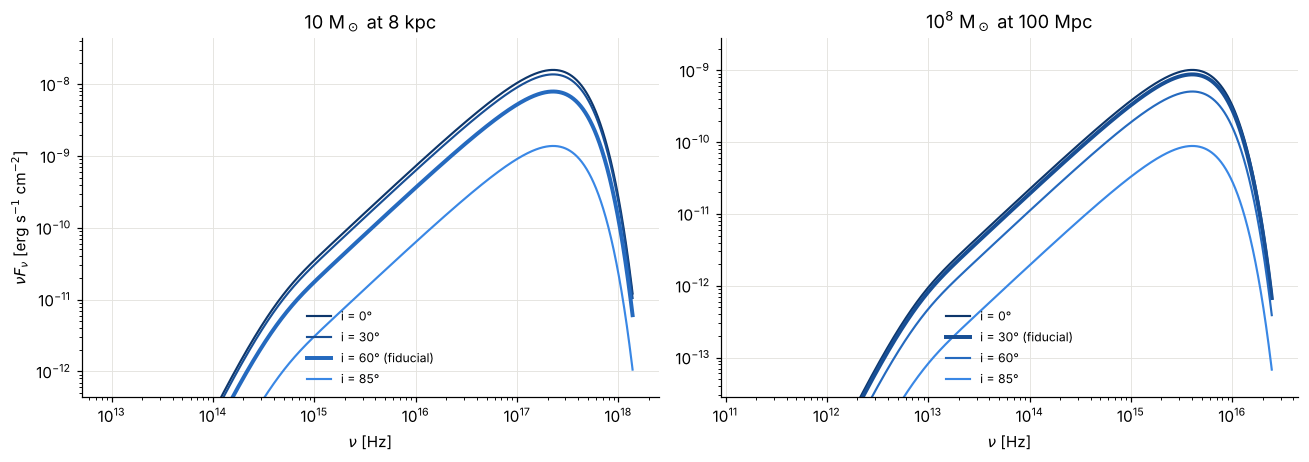

X-ray binary  (i = 60°): F_bol = 1.641e-08 erg/s/cm^2,  L_iso / L_true = 1.000  (2 cos i = 1.000)


AGN           (i = 30°): F_bol = 1.819e-09 erg/s/cm^2,  L_iso / L_true = 1.732  (2 cos i = 1.732)


In [13]:
observers = [("10 M$_\\odot$ at 8 kpc", "X-ray binary", stellar, 8 * C.kpc, 60.0),
             ("10$^8$ M$_\\odot$ at 100 Mpc", "AGN", smbh, 100 * C.Mpc, 30.0)]
incs = [0, 30, 60, 85]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, (title, _, d, D, i_fid) in zip(axes, observers):
    nu = d.frequency_grid(2000, low=1e-4, high=15)
    for color, inc in zip(BLUE_RAMP[2:][::-1], incs):
        ax.loglog(nu, nu * d.flux_nu(nu, D, inc), color=color, lw=2.6 if inc == i_fid else 1.4,
                  label=f"i = {inc}°" + (" (fiducial)" if inc == i_fid else ""))
    top = ax.get_ylim()[1]; ax.set_ylim(top * 1e-5, top)
    ax.set(xlabel=r"$\nu$ [Hz]", title=title); ax.legend(fontsize=8, loc="lower center")
axes[0].set_ylabel(r"$\nu F_\nu$ [erg s$^{-1}$ cm$^{-2}$]"); plt.tight_layout(); plt.show()

for _, name, d, D, inc in observers:
    nu = d.frequency_grid(4000)
    F = np.trapezoid(d.flux_nu(nu, D, inc), nu)
    L_iso = 4 * np.pi * D**2 * F
    print(f"{name:13s} (i = {inc:g}°): F_bol = {F:.3e} erg/s/cm^2,  "
          f"L_iso / L_true = {L_iso / d.bolometric_luminosity():.3f}  (2 cos i = {2 * np.cos(np.radians(inc)):.3f})")

Two points for interpreting observations:

* **Inclination changes only the normalisation in this model.** Without relativistic effects, the spectral shape is the same at every viewing angle.
* **Assuming isotropic emission is biased.** An observer who computes $L_{\rm iso} = 4\pi D^2 F$ gets $2\cos i\,L$. That overestimates $L$ by up to 2× near face-on and underestimates it badly near edge-on.

Use the helper below to explore any combination of parameters:

M = 1e+04 Msun, L/L_Edd = 0.5:  Mdot = 1.332e-04 Msun/yr, L = 6.284e+41 erg/s
T_max = 1.176e+06 K, nu_peak = 6.041e+16 Hz = 0.25 keV = 49.6 A
at D = 3e+06 pc, i = 45°:  F_bol = 8.253e-10 erg/s/cm^2


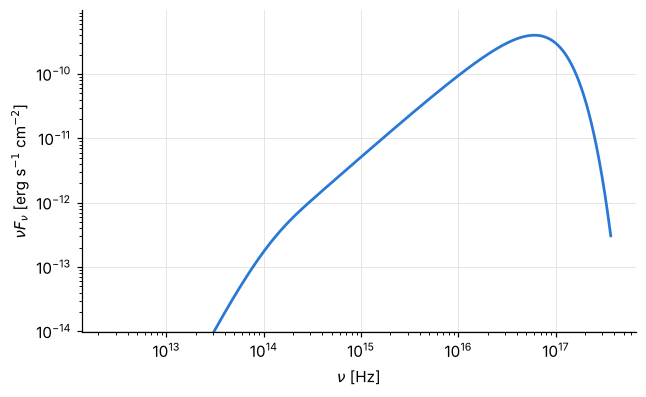

In [14]:
def explore(mass_msun, eddington_ratio, distance_pc, inclination_deg):
    d = ThinDisk.from_eddington(mass_msun, eddington_ratio)
    D = distance_pc * C.pc
    nu = d.frequency_grid(1500, low=1e-4, high=15)
    nu_p = d.peak_frequency()
    F = np.trapezoid(d.flux_nu(nu, D, inclination_deg), nu)
    print(f"M = {mass_msun:.3g} Msun, L/L_Edd = {eddington_ratio:g}:  Mdot = {d.mdot * C.yr / C.M_sun:.3e} Msun/yr, "
          f"L = {d.bolometric_luminosity():.3e} erg/s")
    print(f"T_max = {d.T_max:.3e} K, nu_peak = {nu_p:.3e} Hz = {C.h * nu_p / C.keV:.3g} keV = {C.c / nu_p / C.angstrom:.3g} A")
    print(f"at D = {distance_pc:.3g} pc, i = {inclination_deg}°:  F_bol = {F:.3e} erg/s/cm^2")
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.loglog(nu, nu * d.flux_nu(nu, D, inclination_deg), color=BLUE)
    top = ax.get_ylim()[1]; ax.set_ylim(top * 1e-5, top)
    ax.set(xlabel=r"$\nu$ [Hz]", ylabel=r"$\nu F_\nu$ [erg s$^{-1}$ cm$^{-2}$]"); plt.show()

# e.g. an intermediate-mass black hole in a nearby galaxy
explore(mass_msun=1e4, eddington_ratio=0.5, distance_pc=3e6, inclination_deg=45)

## 9. Summary and limitations

**What the model shows**

| Quantity | Scaling | Consequence |
|---|---|---|
| $T_{\max}$ | $(\dot M/M^2)^{1/4}$; at fixed $\lambda$, $M^{-1/4}$ | stellar disks are hot (~10⁷ K), AGN disks are warm (~10⁵ K) |
| $\nu_{\rm peak}$ | $\approx 2.47\,kT_{\max}/h$ | X-rays for $10\,M_\odot$, UV for $10^8\,M_\odot$ |
| $L_{\rm bol}$ | $\dot M c^2/12$, independent of $M$ | luminosity measures $\dot M$; the peak is needed for $M$ |
| $F_\nu$ | $\cos i / D^2$ | inclination biases $L_{\rm iso}$ by a factor of $2\cos i$ |
| Spectral shape | $\nu^2 \to \nu^{1/3} \to$ Wien | universal in units of $kT_{\max}$ |

**What it leaves out**

* **General relativity in the disk structure.** The Novikov–Thorne profile and black hole spin, which moves the ISCO from 6 down to 1 $GM/c^2$ and raises the efficiency from about 6% to as much as 42%, would give hotter inner disks and higher $\nu_{\rm peak}$.
* **Relativistic photon transport.** Doppler beaming (orbital speeds of about $0.4c$ at the ISCO), gravitational redshift and light bending make the spectral shape depend on inclination, not just the normalisation.
* **Non-blackbody emission.** Electron scattering hardens the spectrum (color correction $f_{\rm col} \approx 1.7$ in X-ray binaries). Absorption edges and limb darkening also distort it.
* **Other emission components.** The model omits the Comptonizing corona, reflection and Fe Kα, jets, outer-disk irradiation, the companion star or host galaxy, and the AGN dust torus.
* **Range of validity.** The thin-disk assumption fails near and above $L_{\rm Edd}$ (slim disks) and at very low $\dot M$ (radiatively inefficient flows). AGN disks become self-gravitating beyond about $10^3$–$10^4\,r_g$.
* **Propagation effects.** The model includes no interstellar absorption (which removes most of the EUV) and no cosmological redshift.

See `README.md` for references and `scripts/run_analysis.py` for the full set of figures.